In [1]:

# ==========================================
# STEP 1: IMPORT LIBRARIES
# ==========================================

import os
import time
import random
import copy
import json
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

# ==========================================
# DEVICE
# ==========================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Libraries imported successfully!
Device: cuda
GPU: Tesla T4


In [2]:

# ==========================================
# STEP 2: LOAD DATA
# ==========================================

DATA_PATH = "/kaggle/input/datasets/uciml/human-activity-recognition-with-smartphones"

train_df = pd.read_csv(
    os.path.join(DATA_PATH, "train.csv")
)

test_df = pd.read_csv(
    os.path.join(DATA_PATH, "test.csv")
)

print("Train Shape:", train_df.shape)
print("Test Shape:", test_df.shape)

print("\nTrain Columns:")
print(train_df.columns.tolist())

print("\nFirst 5 Rows:")
display(train_df.head())


Train Shape: (7352, 563)
Test Shape: (2947, 563)

Train Columns:
['tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z', 'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z', 'tBodyAcc-mad()-X', 'tBodyAcc-mad()-Y', 'tBodyAcc-mad()-Z', 'tBodyAcc-max()-X', 'tBodyAcc-max()-Y', 'tBodyAcc-max()-Z', 'tBodyAcc-min()-X', 'tBodyAcc-min()-Y', 'tBodyAcc-min()-Z', 'tBodyAcc-sma()', 'tBodyAcc-energy()-X', 'tBodyAcc-energy()-Y', 'tBodyAcc-energy()-Z', 'tBodyAcc-iqr()-X', 'tBodyAcc-iqr()-Y', 'tBodyAcc-iqr()-Z', 'tBodyAcc-entropy()-X', 'tBodyAcc-entropy()-Y', 'tBodyAcc-entropy()-Z', 'tBodyAcc-arCoeff()-X,1', 'tBodyAcc-arCoeff()-X,2', 'tBodyAcc-arCoeff()-X,3', 'tBodyAcc-arCoeff()-X,4', 'tBodyAcc-arCoeff()-Y,1', 'tBodyAcc-arCoeff()-Y,2', 'tBodyAcc-arCoeff()-Y,3', 'tBodyAcc-arCoeff()-Y,4', 'tBodyAcc-arCoeff()-Z,1', 'tBodyAcc-arCoeff()-Z,2', 'tBodyAcc-arCoeff()-Z,3', 'tBodyAcc-arCoeff()-Z,4', 'tBodyAcc-correlation()-X,Y', 'tBodyAcc-correlation()-X,Z', 'tBodyAcc-correlation()-Y,Z', 'tGravityA

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING


In [3]:

# ==========================================
# STEP 3: DATA EXPLORATION
# ==========================================

print("Train Information:")
train_df.info()

print("\nMissing Values:")
print(train_df.isnull().sum().sum())

print("\nDuplicated Rows:")
print(train_df.duplicated().sum())

print("\nActivity Distribution:")
print(train_df["Activity"].value_counts())

print("\nNumber of Subjects:")
print(train_df["subject"].nunique())

print("\nTrain Subject IDs:")
print(sorted(train_df["subject"].unique()))

print("\nTest Subject IDs:")
print(sorted(test_df["subject"].unique()))


Train Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7352 entries, 0 to 7351
Columns: 563 entries, tBodyAcc-mean()-X to Activity
dtypes: float64(561), int64(1), object(1)
memory usage: 31.6+ MB

Missing Values:
0

Duplicated Rows:
0

Activity Distribution:
Activity
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64

Number of Subjects:
21

Train Subject IDs:
[np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]

Test Subject IDs:
[np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)]


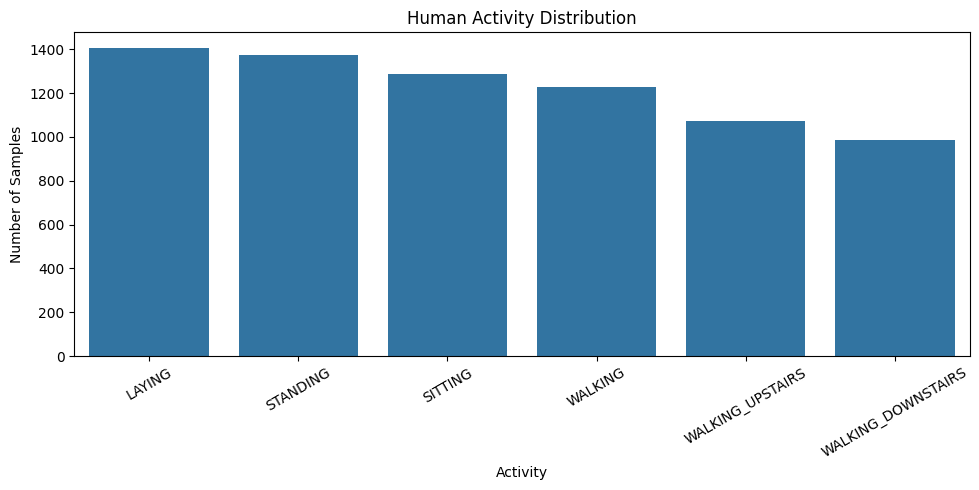

In [6]:

# ==========================================
# STEP 4: ACTIVITY DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 5))

sns.countplot(
    data=train_df,
    x="Activity",
    order=train_df["Activity"].value_counts().index
)

plt.title("Human Activity Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


In [7]:

# ==========================================
# STEP 5: PREPARE FEATURES AND TARGET
# ==========================================

TARGET = "Activity"
GROUP_COLUMN = "subject"

# Separate features and labels
X = train_df.drop(
    columns=[TARGET, GROUP_COLUMN]
)

y = train_df[TARGET]

groups = train_df[GROUP_COLUMN]

# Official test data
X_test = test_df.drop(
    columns=[TARGET, GROUP_COLUMN]
)

y_test = test_df[TARGET]

# Check feature consistency
assert list(X.columns) == list(X_test.columns), \
    "Train and Test features do not match!"

print("Training Features:", X.shape)
print("Training Labels:", y.shape)

print("Test Features:", X_test.shape)
print("Test Labels:", y_test.shape)

print("\nClasses:")
print(y.unique())

print("\nFeature count:", X.shape[1])


Training Features: (7352, 561)
Training Labels: (7352,)
Test Features: (2947, 561)
Test Labels: (2947,)

Classes:
['STANDING' 'SITTING' 'LAYING' 'WALKING' 'WALKING_DOWNSTAIRS'
 'WALKING_UPSTAIRS']

Feature count: 561


In [8]:

# ==========================================
# STEP 6: LABEL ENCODING
# ==========================================

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

y_test_encoded = label_encoder.transform(y_test)

class_names = label_encoder.classes_

NUM_CLASSES = len(class_names)
INPUT_DIM = X.shape[1]

print("Class Mapping:")

for i, name in enumerate(class_names):
    print(f"{i} -> {name}")

print("\nNumber of Classes:", NUM_CLASSES)
print("Input Dimension:", INPUT_DIM)


Class Mapping:
0 -> LAYING
1 -> SITTING
2 -> STANDING
3 -> WALKING
4 -> WALKING_DOWNSTAIRS
5 -> WALKING_UPSTAIRS

Number of Classes: 6
Input Dimension: 561


In [9]:

# ==========================================
# STEP 7: GROUP-BASED SPLIT
# ==========================================

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y_encoded, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()

y_train = y_encoded[train_idx]
y_val = y_encoded[val_idx]

groups_train = groups.iloc[train_idx]
groups_val = groups.iloc[val_idx]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

print("\nTraining Subjects:")
print(sorted(groups_train.unique()))

print("\nValidation Subjects:")
print(sorted(groups_val.unique()))

# Check for subject leakage
overlap = set(groups_train.unique()) & set(groups_val.unique())

print("\nOverlapping Subjects:", overlap)

assert len(overlap) == 0, "Data Leakage Detected!"

print("\nNo Subject Leakage!")


X_train: (5551, 561)
X_val: (1801, 561)

Training Subjects:
[np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(26), np.int64(28), np.int64(29), np.int64(30)]

Validation Subjects:
[np.int64(1), np.int64(3), np.int64(15), np.int64(25), np.int64(27)]

Overlapping Subjects: set()

No Subject Leakage!


In [10]:

# ==========================================
# STEP 8: FEATURE SCALING
# ==========================================

scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation and test
X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

# Convert labels to numpy arrays
y_train = np.asarray(y_train, dtype=np.int64)
y_val = np.asarray(y_val, dtype=np.int64)
y_test_encoded = np.asarray(y_test_encoded, dtype=np.int64)

print("Scaled Training:", X_train_scaled.shape)
print("Scaled Validation:", X_val_scaled.shape)
print("Scaled Test:", X_test_scaled.shape)

print("\nTraining Mean:", X_train_scaled.mean())
print("Training Std:", X_train_scaled.std())


Scaled Training: (5551, 561)
Scaled Validation: (1801, 561)
Scaled Test: (2947, 561)

Training Mean: 7.164497958764843e-19
Training Std: 1.0


,Activity,Train,Validation
0,LAYING,1076,331
1,SITTING,993,293
2,STANDING,1053,321
3,WALKING,888,338
4,WALKING_DOWNSTAIRS,744,242
5,WALKING_UPSTAIRS,797,276


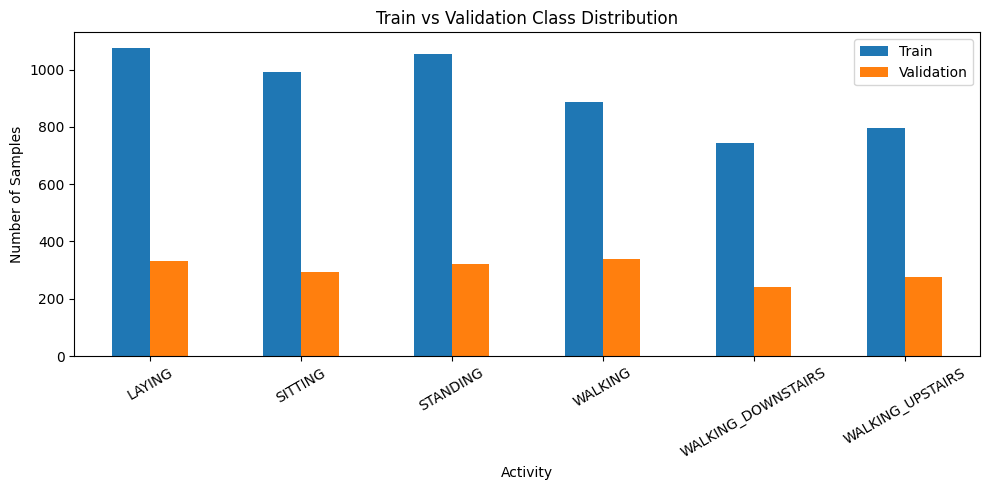

In [11]:

# ==========================================
# STEP 9: CLASS DISTRIBUTION
# ==========================================

train_distribution = pd.Series(
    y_train
).value_counts().sort_index()

val_distribution = pd.Series(
    y_val
).value_counts().sort_index()

distribution_df = pd.DataFrame({
    "Activity": class_names,
    "Train": train_distribution.values,
    "Validation": val_distribution.values
})

display(distribution_df)

distribution_df.set_index("Activity").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Train vs Validation Class Distribution")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


Baseline Model

In [12]:

# ==========================================
# STEP 10: RANDOM FOREST BASELINE
# ==========================================

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

# Training time
start_time = time.time()

rf_model.fit(
    X_train_scaled,
    y_train
)

rf_training_time = time.time() - start_time

# Inference time
start_time = time.time()

rf_predictions = rf_model.predict(X_val_scaled)

rf_inference_time = (
    time.time() - start_time
) / len(X_val_scaled)

# Evaluation
rf_accuracy = accuracy_score(
    y_val,
    rf_predictions
)

rf_precision = precision_score(
    y_val,
    rf_predictions,
    average="macro",
    zero_division=0
)

rf_recall = recall_score(
    y_val,
    rf_predictions,
    average="macro",
    zero_division=0
)

rf_f1 = f1_score(
    y_val,
    rf_predictions,
    average="macro",
    zero_division=0
)

print("Random Forest Results")
print("=" * 40)

print("Accuracy:", rf_accuracy)
print("Macro Precision:", rf_precision)
print("Macro Recall:", rf_recall)
print("Macro F1:", rf_f1)

print("Training Time:", rf_training_time)
print("Inference Time per Sample:", rf_inference_time)

print("\nClassification Report:")

print(
    classification_report(
        y_val,
        rf_predictions,
        target_names=class_names,
        zero_division=0
    )
)


Random Forest Results
Accuracy: 0.9339255968906163
Macro Precision: 0.9403569713443612
Macro Recall: 0.9248107519874091
Macro F1: 0.9252805237471208
Training Time: 8.278926849365234
Inference Time per Sample: 4.329236595581665e-05

Classification Report:
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       331
           SITTING       0.89      0.99      0.94       293
          STANDING       0.98      0.89      0.93       321
           WALKING       0.95      1.00      0.97       338
WALKING_DOWNSTAIRS       1.00      0.68      0.81       242
  WALKING_UPSTAIRS       0.82      0.99      0.90       276

          accuracy                           0.93      1801
         macro avg       0.94      0.92      0.93      1801
      weighted avg       0.94      0.93      0.93      1801



In [14]:

# Random Forest - 3 Random Seeds

rf_seed_results = []

for seed in [21, 42, 2026]:

    model = RandomForestClassifier(
        n_estimators=200,
        random_state=seed,
        n_jobs=-1
    )

    start = time.time()

    model.fit(X_train_scaled, y_train)

    training_time = time.time() - start

    predictions = model.predict(X_val_scaled)

    rf_seed_results.append({
        "Seed": seed,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(
            y_val, predictions, average="macro"
        ),
        "Training Time": training_time
    })

rf_seeds_df = pd.DataFrame(rf_seed_results)

display(rf_seeds_df)

print("\nMean and Standard Deviation:")
display(
    rf_seeds_df[
        ["Accuracy", "Macro F1", "Training Time"]
    ].agg(["mean", "std"])
)


,Seed,Accuracy,Macro F1,Training Time
0,21,0.934481,0.927215,8.312588
1,42,0.933926,0.925281,8.281232
2,2026,0.935036,0.927561,8.184974



Mean and Standard Deviation:


,Accuracy,Macro F1,Training Time
mean,0.934481,0.926685,8.259598
std,0.000555,0.001229,0.066501


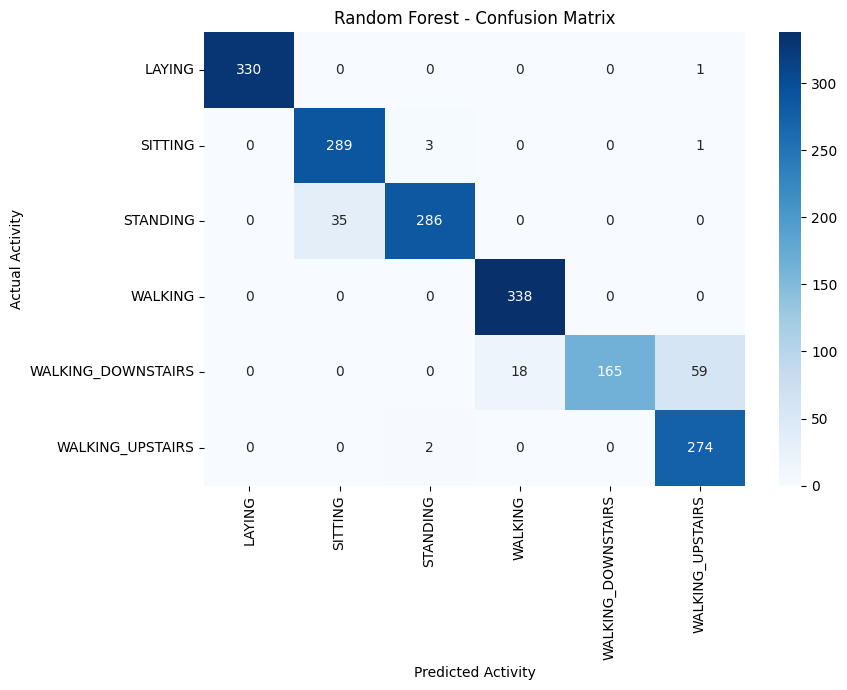

In [16]:

# ==========================================
# STEP 11: BASELINE CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    y_val,
    rf_predictions
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")

plt.tight_layout()
plt.show()


In [18]:

# STEP 11.1: BASELINE ERROR ANALYSIS

wrong_mask = y_val != rf_predictions

errors_df = pd.DataFrame({
    "Sample_Index": X_val.index[wrong_mask],
    "Subject": np.asarray(groups_val)[wrong_mask],
    "Actual": class_names[y_val[wrong_mask]],
    "Predicted": class_names[rf_predictions[wrong_mask]]
})

print("Total Errors:", len(errors_df))

print("\nTop Misclassification Types:")
error_summary = (
    errors_df.groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

display(error_summary)

print("\nExample Misclassified Samples:")
display(errors_df.head(10))


Total Errors: 119

Top Misclassification Types:


,Actual,Predicted,Count
5,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS,59
3,STANDING,SITTING,35
4,WALKING_DOWNSTAIRS,WALKING,18
1,SITTING,STANDING,3
6,WALKING_UPSTAIRS,STANDING,2
2,SITTING,WALKING_UPSTAIRS,1
0,LAYING,WALKING_UPSTAIRS,1



Example Misclassified Samples:


,Sample_Index,Subject,Actual,Predicted
0,13,1,STANDING,SITTING
1,22,1,STANDING,SITTING
2,23,1,STANDING,SITTING
3,70,1,LAYING,WALKING_UPSTAIRS
4,125,1,WALKING_DOWNSTAIRS,WALKING
5,126,1,WALKING_DOWNSTAIRS,WALKING
6,132,1,WALKING_DOWNSTAIRS,WALKING
7,133,1,WALKING_DOWNSTAIRS,WALKING
8,144,1,WALKING_DOWNSTAIRS,WALKING
9,147,1,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS


In [19]:

# ==========================================
# STEP 12: PYTORCH DATA PREPARATION
# ==========================================

X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_scaled,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)

y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test_encoded,
    dtype=torch.long
)

print("Tensor Shapes:")
print("Train:", X_train_tensor.shape)
print("Validation:", X_val_tensor.shape)
print("Test:", X_test_tensor.shape)


Tensor Shapes:
Train: torch.Size([5551, 561])
Validation: torch.Size([1801, 561])
Test: torch.Size([2947, 561])


In [20]:

# ==========================================
# STEP 13: DATA LOADERS
# ==========================================

BATCH_SIZE = 64

def create_loaders(seed=42):

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_dataset = TensorDataset(
        X_train_tensor,
        y_train_tensor
    )

    val_dataset = TensorDataset(
        X_val_tensor,
        y_val_tensor
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    return train_loader, val_loader


train_loader, val_loader = create_loaders()

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Training batches: 87
Validation batches: 29


Model 1

In [21]:

# ==========================================
# STEP 14: 1D CNN MODEL
# ==========================================

class CNN1D(nn.Module):

    def __init__(self, input_dim=561, num_classes=6):

        super(CNN1D, self).__init__()

        self.features = nn.Sequential(

            nn.Conv1d(
                in_channels=1,
                out_channels=32,
                kernel_size=7,
                padding=3
            ),

            nn.BatchNorm1d(32),
            nn.ReLU(),

            nn.Conv1d(
                32,
                64,
                kernel_size=5,
                padding=2
            ),

            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(128, 64),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        # [Batch, Features]
        # to [Batch, Channels, Features]

        x = x.unsqueeze(1)

        x = self.features(x)

        x = self.classifier(x)

        return x


cnn_model = CNN1D(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES
).to(device)

print(cnn_model)


CNN1D(
  (features): Sequential(
    (0): Conv1d(1, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (8): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
    (10): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=128, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=6, bias=True)
  )
)


In [22]:

# ==========================================
# STEP 15: TRANSFORMER MODEL
# ==========================================

class FeatureTransformer(nn.Module):

    def __init__(
        self,
        input_dim=561,
        num_classes=6,
        d_model=64,
        num_heads=4,
        num_layers=2,
        dropout=0.2
    ):

        super().__init__()

        self.input_projection = nn.Linear(
            1,
            d_model
        )

        self.positional_embedding = nn.Parameter(
            torch.randn(1, input_dim, d_model) * 0.02
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=128,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.classifier = nn.Sequential(

            nn.LayerNorm(d_model),

            nn.Linear(d_model, 64),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        # [Batch, 561]
        x = x.unsqueeze(-1)

        # [Batch, 561, 64]
        x = self.input_projection(x)

        x = x + self.positional_embedding

        x = self.encoder(x)

        # Mean pooling
        x = x.mean(dim=1)

        x = self.classifier(x)

        return x


transformer_model = FeatureTransformer(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES
).to(device)

print(transformer_model)


FeatureTransformer(
  (input_projection): Linear(in_features=1, out_features=64, bias=True)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
  )
  (classifier): Sequential(
    (0): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_features=64, out_features=64, bias=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.2, i

In [23]:

# ==========================================
# STEP 16: CUSTOM FEATURE ATTENTION
# ==========================================

class FeatureAttention(nn.Module):

    def __init__(self, input_dim=561):

        super().__init__()

        self.attention = nn.Sequential(

            nn.Linear(input_dim, 256),

            nn.ReLU(),

            nn.Linear(256, input_dim),

            nn.Sigmoid()
        )

    def forward(self, x):

        weights = self.attention(x)

        attended_features = x * weights

        return attended_features, weights


# ==========================================
# ADVANCED RESIDUAL MODEL
# ==========================================

class AdvancedHARModel(nn.Module):

    def __init__(
        self,
        input_dim=561,
        num_classes=6,
        hidden_dim=256,
        dropout=0.3
    ):

        super().__init__()

        self.attention = FeatureAttention(input_dim)

        self.input_layer = nn.Sequential(

            nn.Linear(input_dim, hidden_dim),

            nn.BatchNorm1d(hidden_dim),

            nn.GELU()
        )

        self.residual_block = nn.Sequential(

            nn.Linear(hidden_dim, hidden_dim),

            nn.BatchNorm1d(hidden_dim),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(hidden_dim, hidden_dim),

            nn.BatchNorm1d(hidden_dim)
        )

        self.activation = nn.GELU()

        self.classifier = nn.Sequential(

            nn.Linear(hidden_dim, 128),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        attended, weights = self.attention(x)

        x = self.input_layer(attended)

        residual = x

        x = self.residual_block(x)

        x = self.activation(x + residual)

        output = self.classifier(x)

        return output


advanced_model = AdvancedHARModel(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES
).to(device)

print(advanced_model)


AdvancedHARModel(
  (attention): FeatureAttention(
    (attention): Sequential(
      (0): Linear(in_features=561, out_features=256, bias=True)
      (1): ReLU()
      (2): Linear(in_features=256, out_features=561, bias=True)
      (3): Sigmoid()
    )
  )
  (input_layer): Sequential(
    (0): Linear(in_features=561, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
  )
  (residual_block): Sequential(
    (0): Linear(in_features=256, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (activation): GELU(approximate='none')
  (classifier): Sequential(
    (0): Linear(in_features=256, out_featu

In [24]:

# ==========================================
# STEP 17: MODEL PARAMETERS
# ==========================================

models = {
    "CNN": CNN1D(INPUT_DIM, NUM_CLASSES),
    "Transformer": FeatureTransformer(INPUT_DIM, NUM_CLASSES),
    "Advanced": AdvancedHARModel(INPUT_DIM, NUM_CLASSES)
}

for name, model in models.items():

    total_params = sum(
        p.numel() for p in model.parameters()
    )

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    print("\nModel:", name)
    print("Total Parameters:", total_params)
    print("Trainable Parameters:", trainable_params)



Model: CNN
Total Parameters: 44358
Trainable Parameters: 44358

Model: Transformer
Total Parameters: 107654
Trainable Parameters: 107654

Model: Advanced
Total Parameters: 598711
Trainable Parameters: 598711


In [25]:

# STEP 17.1: MODEL SIZE COMPARISON

model_info = []

for name, model in models.items():

    total_params = sum(
        p.numel() for p in model.parameters()
    )

    model_size_mb = sum(
        t.numel() * t.element_size()
        for t in model.state_dict().values()
    ) / (1024 ** 2)

    model_info.append({
        "Model": name,
        "Parameters": total_params,
        "Approx State Size (MB)": round(model_size_mb, 3)
    })

model_info_df = pd.DataFrame(model_info)

display(model_info_df)


,Model,Parameters,Approx State Size (MB)
0,CNN,44358,0.171
1,Transformer,107654,0.411
2,Advanced,598711,2.290


In [26]:

# ==========================================
# STEP 18: REPRODUCIBILITY
# ==========================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


SEEDS = [21, 42, 2026]

print("Seeds:", SEEDS)


Seeds: [21, 42, 2026]


In [27]:

# ==========================================
# STEP 19: TRAINING FUNCTION
# ==========================================

def train_model(
    model,
    train_loader,
    val_loader,
    seed,
    epochs=40,
    learning_rate=0.001,
    patience=7
):

    set_seed(seed)

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3
    )

    best_val_loss = float("inf")

    best_state = None

    counter = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    start_time = time.time()

    for epoch in range(epochs):

        # ----------------------
        # TRAINING
        # ----------------------

        model.train()

        train_loss = 0
        train_correct = 0
        train_total = 0

        for inputs, labels in train_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            train_loss += loss.item() * inputs.size(0)

            predictions = outputs.argmax(dim=1)

            train_correct += (
                predictions == labels
            ).sum().item()

            train_total += labels.size(0)

        train_loss /= train_total

        train_accuracy = train_correct / train_total

        # ----------------------
        # VALIDATION
        # ----------------------

        model.eval()

        val_loss = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for inputs, labels in val_loader:

                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)

                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)

                predictions = outputs.argmax(dim=1)

                val_correct += (
                    predictions == labels
                ).sum().item()

                val_total += labels.size(0)

        val_loss /= val_total

        val_accuracy = val_correct / val_total

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        # ----------------------
        # EARLY STOPPING
        # ----------------------

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_state = copy.deepcopy(
                model.state_dict()
            )

            counter = 0

        else:

            counter += 1

        if (epoch + 1) % 5 == 0:

            print(
                f"Epoch {epoch+1}/{epochs} | "
                f"Train Loss: {train_loss:.4f} | "
                f"Val Loss: {val_loss:.4f} | "
                f"Val Acc: {val_accuracy:.4f}"
            )

        if counter >= patience:

            print("Early Stopping!")

            break

    training_time = time.time() - start_time

    if best_state is not None:

        model.load_state_dict(best_state)

    return model, history, training_time


In [28]:

# ==========================================
# STEP 20: EVALUATION FUNCTION
# ==========================================

def evaluate_model(model, X_data, y_data):

    model.eval()

    X_data = X_data.to(device)

    start_time = time.time()

    with torch.no_grad():

        outputs = model(X_data)

        predictions = outputs.argmax(dim=1)

    total_inference_time = time.time() - start_time

    predictions = predictions.cpu().numpy()

    y_true = y_data.cpu().numpy()

    results = {

        "Accuracy": accuracy_score(
            y_true, predictions
        ),

        "Macro Precision": precision_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Inference Time": (
            total_inference_time / len(y_true)
        )
    }

    return results, predictions


In [29]:

# ==========================================
# STEP 20.1: MEMORY-EFFICIENT EVALUATION
# ==========================================

def evaluate_model(model, X_data, y_data, batch_size=16):

    model = model.to(device)
    model.eval()

    predictions_list = []
    total_inference_time = 0

    with torch.inference_mode():

        for i in range(0, len(X_data), batch_size):

            batch = X_data[i:i + batch_size].to(device)

            if device.type == "cuda":
                torch.cuda.synchronize()

            start = time.perf_counter()

            outputs = model(batch)

            if device.type == "cuda":
                torch.cuda.synchronize()

            total_inference_time += (
                time.perf_counter() - start
            )

            predictions_list.append(
                outputs.argmax(dim=1).cpu().numpy()
            )

    predictions = np.concatenate(predictions_list)
    y_true = y_data.cpu().numpy()

    results = {
        "Accuracy": accuracy_score(y_true, predictions),

        "Macro Precision": precision_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),

        "Macro Recall": recall_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),

        "Macro F1": f1_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true, predictions,
            average="weighted", zero_division=0
        ),

        "Inference Time": (
            total_inference_time / len(y_true)
        )
    }

    return results, predictions


print("Updated evaluation function ready!")


Updated evaluation function ready!


In [30]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("GPU Available:", torch.cuda.is_available())

Device: cuda
GPU Available: True


In [31]:

# ==========================================
# STEP 21: EXPERIMENT CONFIGURATIONS
# ==========================================

def build_cnn():
    return CNN1D(
        INPUT_DIM,
        NUM_CLASSES
    )

def build_transformer():
    return FeatureTransformer(
        INPUT_DIM,
        NUM_CLASSES
    )

def build_advanced():
    return AdvancedHARModel(
        INPUT_DIM,
        NUM_CLASSES
    )


MODEL_BUILDERS = {
    "CNN": build_cnn,
    "Transformer": build_transformer,
    "Advanced": build_advanced
}

all_results = []

trained_models = {}

histories = {}

for model_name, builder in MODEL_BUILDERS.items():

    for seed in SEEDS:

        print("\n" + "=" * 55)

        print(f"Model: {model_name} | Seed: {seed}")

        print("=" * 55)

        set_seed(seed)

        train_loader, val_loader = create_loaders(seed)

        model = builder()

        model, history, training_time = train_model(
            model,
            train_loader,
            val_loader,
            seed=seed,
            epochs=40,
            learning_rate=0.001,
            patience=7
        )

        metrics, predictions = evaluate_model(
            model,
            X_val_tensor,
            y_val_tensor
        )

        metrics["Model"] = model_name
        metrics["Seed"] = seed
        metrics["Training Time"] = training_time

        all_results.append(metrics)

        key = f"{model_name}_seed{seed}"

        trained_models[key] = model

        histories[key] = history

        print("\nResults:", metrics)

results_df = pd.DataFrame(all_results)

display(
    results_df.sort_values(
        by="Macro F1",
        ascending=False
    )
)



Model: CNN | Seed: 21
Epoch 5/40 | Train Loss: 0.6282 | Val Loss: 0.9372 | Val Acc: 0.5758
Epoch 10/40 | Train Loss: 0.4695 | Val Loss: 0.7692 | Val Acc: 0.6469
Epoch 15/40 | Train Loss: 0.3728 | Val Loss: 1.1191 | Val Acc: 0.5863
Epoch 20/40 | Train Loss: 0.3143 | Val Loss: 0.3985 | Val Acc: 0.8556
Early Stopping!

Results: {'Accuracy': 0.8334258745141588, 'Macro Precision': 0.847166021777586, 'Macro Recall': 0.8253569743050623, 'Macro F1': 0.8268164178946228, 'Weighted F1': 0.8307467455150745, 'Inference Time': 4.9455027762985595e-05, 'Model': 'CNN', 'Seed': 21, 'Training Time': 17.51060724258423}

Model: CNN | Seed: 42
Epoch 5/40 | Train Loss: 0.5947 | Val Loss: 0.9298 | Val Acc: 0.5552
Epoch 10/40 | Train Loss: 0.4228 | Val Loss: 1.1420 | Val Acc: 0.5136
Epoch 15/40 | Train Loss: 0.3600 | Val Loss: 0.7447 | Val Acc: 0.7263
Epoch 20/40 | Train Loss: 0.2481 | Val Loss: 0.3147 | Val Acc: 0.8656
Epoch 25/40 | Train Loss: 0.1897 | Val Loss: 0.2994 | Val Acc: 0.8867
Early Stopping!

Res

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Inference Time,Model,Seed,Training Time
8,0.970017,0.970373,0.966284,0.967318,0.969824,0.000039,Advanced,2026,3.342466
6,0.965019,0.965071,0.960822,0.961663,0.964855,0.000039,Advanced,21,6.983690
7,0.961688,0.963301,0.955814,0.958180,0.961051,0.000038,Advanced,42,2.898439
5,0.958356,0.958706,0.955980,0.956402,0.958549,0.000240,Transformer,2026,198.438974
4,0.934481,0.937989,0.929335,0.929808,0.934801,0.000246,Transformer,42,125.753343
3,0.903387,0.916584,0.891522,0.891069,0.901335,0.000246,Transformer,21,119.731702
1,0.889506,0.897026,0.885293,0.885855,0.889366,0.000048,CNN,42,15.496109
2,0.847307,0.857735,0.845089,0.846874,0.848279,0.000046,CNN,2026,15.114032
0,0.833426,0.847166,0.825357,0.826816,0.830747,0.000049,CNN,21,17.510607


In [33]:

comparison_summary = (
    results_df.groupby("Model")
    [["Accuracy", "Macro F1", "Training Time"]]
    .agg(["mean", "std"])
    .round(4)
)

display(comparison_summary)


Accuracy         Macro F1         Training Time         
                mean     std     mean     std          mean      std
Model                                                               
Advanced      0.9656  0.0042   0.9624  0.0046        4.4082   2.2415
CNN           0.8567  0.0292   0.8532  0.0300       16.0402   1.2876
Transformer   0.9321  0.0276   0.9258  0.0329      147.9747  43.8070

In [34]:

# ==========================================
# STEP 23: HYPERPARAMETER STUDY
# ==========================================

learning_rates = [0.001, 0.01]

hyperparameter_results = []

for model_name, builder in MODEL_BUILDERS.items():

    for lr in learning_rates:

        print("\n" + "=" * 50)
        print("Model:", model_name)
        print("Learning Rate:", lr)
        print("=" * 50)

        seed = 42

        set_seed(seed)

        train_loader, val_loader = create_loaders(seed)

        model = builder()

        model, history, training_time = train_model(
            model,
            train_loader,
            val_loader,
            seed=seed,
            epochs=40,
            learning_rate=lr,
            patience=7
        )

        metrics, predictions = evaluate_model(
            model,
            X_val_tensor,
            y_val_tensor
        )

        hyperparameter_results.append({

            "Model": model_name,

            "Learning Rate": lr,

            "Accuracy": metrics["Accuracy"],

            "Macro F1": metrics["Macro F1"],

            "Training Time": training_time

        })


hyperparameter_df = pd.DataFrame(
    hyperparameter_results
)

display(
    hyperparameter_df.sort_values(
        "Macro F1",
        ascending=False
    )
)



Model: CNN
Learning Rate: 0.001
Epoch 5/40 | Train Loss: 0.5964 | Val Loss: 0.6311 | Val Acc: 0.6646
Epoch 10/40 | Train Loss: 0.4277 | Val Loss: 1.0922 | Val Acc: 0.5197
Epoch 15/40 | Train Loss: 0.3366 | Val Loss: 1.5291 | Val Acc: 0.5253
Epoch 20/40 | Train Loss: 0.2711 | Val Loss: 0.5266 | Val Acc: 0.7662
Epoch 25/40 | Train Loss: 0.2455 | Val Loss: 1.7410 | Val Acc: 0.5158
Early Stopping!

Model: CNN
Learning Rate: 0.01
Epoch 5/40 | Train Loss: 0.5858 | Val Loss: 0.6821 | Val Acc: 0.7185
Epoch 10/40 | Train Loss: 0.4672 | Val Loss: 0.4485 | Val Acc: 0.7646
Epoch 15/40 | Train Loss: 0.2975 | Val Loss: 0.7929 | Val Acc: 0.7124
Early Stopping!

Model: Transformer
Learning Rate: 0.001
Epoch 5/40 | Train Loss: 0.3375 | Val Loss: 0.2939 | Val Acc: 0.9200
Epoch 10/40 | Train Loss: 0.2512 | Val Loss: 0.2315 | Val Acc: 0.9345
Epoch 15/40 | Train Loss: 0.1484 | Val Loss: 0.2751 | Val Acc: 0.9234
Epoch 20/40 | Train Loss: 0.1094 | Val Loss: 0.2456 | Val Acc: 0.9345
Early Stopping!

Model: T

,Model,Learning Rate,Accuracy,Macro F1,Training Time
5,Advanced,0.010,0.968906,0.965949,6.589391
4,Advanced,0.001,0.961688,0.958180,2.932829
2,Transformer,0.001,0.937257,0.931801,132.676176
0,CNN,0.001,0.896169,0.895195,16.993972
1,CNN,0.010,0.764575,0.722268,10.446036
3,Transformer,0.010,0.448640,0.340234,216.280077


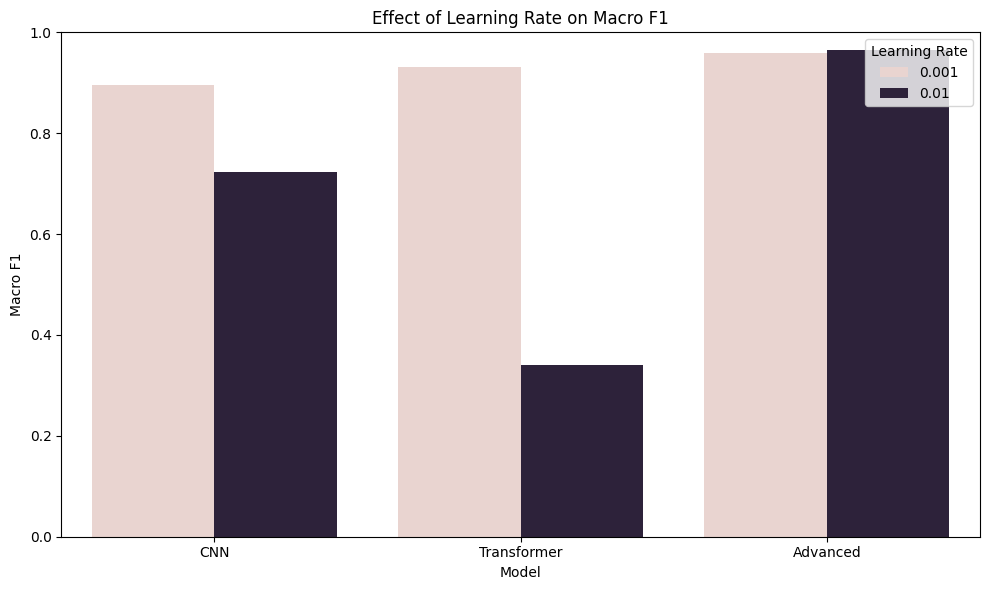

In [35]:

# ==========================================
# STEP 24: HYPERPARAMETER VISUALIZATION
# ==========================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=hyperparameter_df,
    x="Model",
    y="Macro F1",
    hue="Learning Rate"
)

plt.title("Effect of Learning Rate on Macro F1")

plt.ylabel("Macro F1")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


In [36]:

# ==========================================
# STEP 25: GAUSSIAN NOISE AUGMENTATION
# ==========================================

def add_gaussian_noise(X, noise_std=0.05, seed=42):

    rng = np.random.default_rng(seed)

    noise = rng.normal(
        loc=0.0,
        scale=noise_std,
        size=X.shape
    )

    augmented_X = X + noise

    return augmented_X.astype(np.float32)


X_train_augmented = add_gaussian_noise(
    X_train_scaled,
    noise_std=0.05,
    seed=42
)

print("Original Shape:", X_train_scaled.shape)

print("Augmented Shape:", X_train_augmented.shape)

print("Validation Shape:", X_val_scaled.shape)

print("Test Shape:", X_test_scaled.shape)


Original Shape: (5551, 561)
Augmented Shape: (5551, 561)
Validation Shape: (1801, 561)
Test Shape: (2947, 561)


In [37]:

# ==========================================
# STEP 26: DATA STRATEGY COMPARISON
# ==========================================

def make_tensor_loader(X, y, seed=42):

    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long)
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        dataset,
        batch_size=64,
        shuffle=True,
        generator=generator
    )


strategy_results = []

for strategy_name, X_data in [
    ("Original", X_train_scaled),
    ("Gaussian Noise", X_train_augmented)
]:

    print("\nStrategy:", strategy_name)

    seed = 42

    set_seed(seed)

    train_loader = make_tensor_loader(
        X_data,
        y_train,
        seed
    )

    _, val_loader = create_loaders(seed)

    model = build_advanced()

    model, history, training_time = train_model(
        model,
        train_loader,
        val_loader,
        seed=seed,
        epochs=40,
        learning_rate=0.001,
        patience=7
    )

    metrics, predictions = evaluate_model(
        model,
        X_val_tensor,
        y_val_tensor
    )

    strategy_results.append({

        "Strategy": strategy_name,

        "Accuracy": metrics["Accuracy"],

        "Macro F1": metrics["Macro F1"],

        "Training Time": training_time
    })


strategy_df = pd.DataFrame(strategy_results)

display(strategy_df)



Strategy: Original
Epoch 5/40 | Train Loss: 0.0446 | Val Loss: 0.2340 | Val Acc: 0.9384
Early Stopping!

Strategy: Gaussian Noise
Epoch 5/40 | Train Loss: 0.0418 | Val Loss: 0.2147 | Val Acc: 0.9428
Early Stopping!


,Strategy,Accuracy,Macro F1,Training Time
0,Original,0.961688,0.958180,2.953968
1,Gaussian Noise,0.959467,0.955585,2.906136


In [39]:

# ==========================================
# STEP 27: SELF-SUPERVISED PRETRAINING MODEL
# ==========================================

class MaskedFeatureTransformer(nn.Module):

    def __init__(
        self,
        input_dim=561,
        d_model=64,
        num_heads=4,
        num_layers=2,
        dropout=0.2
    ):

        super().__init__()

        self.input_projection = nn.Linear(
            1,
            d_model
        )

        self.positional_embedding = nn.Parameter(
            torch.randn(1, input_dim, d_model) * 0.02
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=128,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # Predict original feature values
        self.reconstruction_head = nn.Linear(
            d_model,
            1
        )

    def forward(self, x):

        # [Batch, Features] -> [Batch, Features, 1]
        x = x.unsqueeze(-1)

        x = self.input_projection(x)

        x = x + self.positional_embedding

        x = self.encoder(x)

        reconstructed = self.reconstruction_head(x)

        return reconstructed.squeeze(-1)


In [43]:

# ==========================================
# STEP 28: UNLABELED TRAINING DATA
# ==========================================

pretrain_dataset = TensorDataset(
    X_train_tensor
)

def create_pretrain_loader(seed=42):

    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        pretrain_dataset,
        batch_size=64,
        shuffle=True,
        generator=generator
    )

pretrain_loader = create_pretrain_loader(42)

print("Pretraining samples:", len(pretrain_dataset))
print("Validation excluded:", len(X_val_tensor))
print("Test excluded:", len(X_test_tensor))


Pretraining samples: 5551
Validation excluded: 1801
Test excluded: 2947


In [45]:

# ==========================================
# STEP 29: PRETRAINING FUNCTION
# ==========================================

def pretrain_transformer(
    model,
    loader,
    seed=42,
    epochs=15,
    learning_rate=0.001,
    mask_ratio=0.30
):

    set_seed(seed)

    model = model.to(device)

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4
    )

    criterion = nn.MSELoss()

    history = []

    start_time = time.time()

    for epoch in range(epochs):

        model.train()

        total_loss = 0
        total_samples = 0

        for (original_x,) in loader:

            original_x = original_x.to(device)

            # Random feature masking
            mask = (
                torch.rand_like(original_x) < mask_ratio
            )

            # Replace masked values with zero
            masked_x = original_x.masked_fill(
                mask,
                0.0
            )

            optimizer.zero_grad()

            reconstructed = model(masked_x)

            # Calculate loss on masked features only
            loss = criterion(
                reconstructed[mask],
                original_x[mask]
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item() * original_x.size(0)

            total_samples += original_x.size(0)

        epoch_loss = total_loss / total_samples

        history.append(epoch_loss)

        print(
            f"Pretraining Epoch {epoch+1}/{epochs} "
            f"| Reconstruction Loss: {epoch_loss:.5f}"
        )

    training_time = time.time() - start_time

    return model, history, training_time


In [46]:

# ==========================================
# STEP 30: RUN PRETRAINING
# ==========================================

PRETRAIN_SEED = 42

set_seed(PRETRAIN_SEED)

pretrained_encoder = MaskedFeatureTransformer(
    input_dim=INPUT_DIM,
    d_model=64,
    num_heads=4,
    num_layers=2
)

pretrained_encoder, pretrain_history, pretrain_time = (
    pretrain_transformer(
        pretrained_encoder,
        create_pretrain_loader(PRETRAIN_SEED),
        seed=PRETRAIN_SEED,
        epochs=15
    )
)

print("\nPretraining completed!")
print("Pretraining Time:", pretrain_time)


Pretraining Epoch 1/15 | Reconstruction Loss: 0.79945
Pretraining Epoch 2/15 | Reconstruction Loss: 0.64846
Pretraining Epoch 3/15 | Reconstruction Loss: 0.51979
Pretraining Epoch 4/15 | Reconstruction Loss: 0.49839
Pretraining Epoch 5/15 | Reconstruction Loss: 0.48563
Pretraining Epoch 6/15 | Reconstruction Loss: 0.48273
Pretraining Epoch 7/15 | Reconstruction Loss: 0.47606
Pretraining Epoch 8/15 | Reconstruction Loss: 0.47196
Pretraining Epoch 9/15 | Reconstruction Loss: 0.46488
Pretraining Epoch 10/15 | Reconstruction Loss: 0.45793
Pretraining Epoch 11/15 | Reconstruction Loss: 0.45511
Pretraining Epoch 12/15 | Reconstruction Loss: 0.44806
Pretraining Epoch 13/15 | Reconstruction Loss: 0.44378
Pretraining Epoch 14/15 | Reconstruction Loss: 0.43614
Pretraining Epoch 15/15 | Reconstruction Loss: 0.43574

Pretraining completed!
Pretraining Time: 93.37435221672058


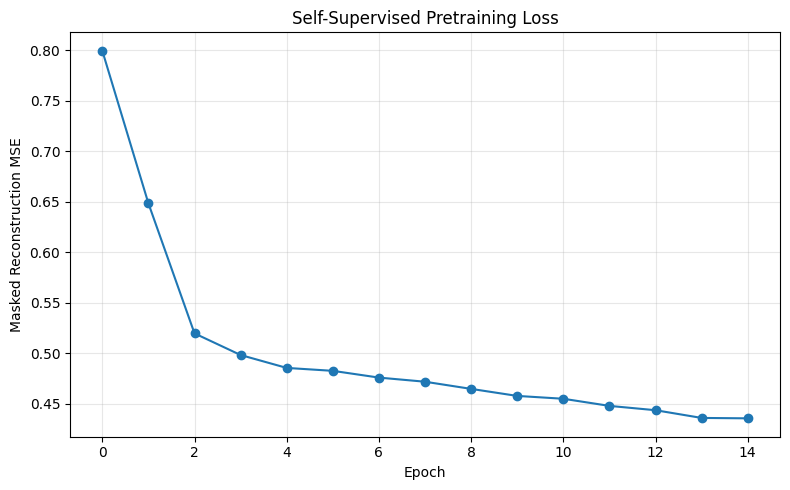

In [47]:

# ==========================================
# STEP 31: PRETRAINING LOSS
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    pretrain_history,
    marker="o"
)

plt.title("Self-Supervised Pretraining Loss")

plt.xlabel("Epoch")
plt.ylabel("Masked Reconstruction MSE")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [48]:

# ==========================================
# STEP 32: TRANSFER LEARNED WEIGHTS
# ==========================================

def transfer_pretrained_weights(
    pretrained_model,
    classification_model
):

    classification_model.input_projection.load_state_dict(
        pretrained_model.input_projection.state_dict()
    )

    classification_model.positional_embedding.data.copy_(
        pretrained_model.positional_embedding.data
    )

    classification_model.encoder.load_state_dict(
        pretrained_model.encoder.state_dict()
    )

    return classification_model


# Create downstream classifier
set_seed(42)

pretrained_classifier = FeatureTransformer(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    d_model=64,
    num_heads=4,
    num_layers=2
)

pretrained_classifier = transfer_pretrained_weights(
    pretrained_encoder,
    pretrained_classifier
)

pretrained_classifier = pretrained_classifier.to(device)

print("Pretrained weights transferred successfully!")


Pretrained weights transferred successfully!


In [49]:

# ==========================================
# STEP 33: SCRATCH VS PRETRAINED
# ==========================================

comparison_results = []

seed = 42

train_loader, val_loader = create_loaders(seed)

# ------------------------------------------
# 1. Transformer From Scratch
# ------------------------------------------

set_seed(seed)

scratch_model = FeatureTransformer(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    d_model=64,
    num_heads=4,
    num_layers=2
).to(device)

scratch_model, scratch_history, scratch_time = train_model(
    scratch_model,
    train_loader,
    val_loader,
    seed=seed,
    epochs=40,
    learning_rate=0.001,
    patience=7
)

scratch_metrics, _ = evaluate_model(
    scratch_model,
    X_val_tensor,
    y_val_tensor
)

comparison_results.append({

    "Strategy": "From Scratch",

    "Macro F1": scratch_metrics["Macro F1"],

    "Accuracy": scratch_metrics["Accuracy"],

    "Training Time": scratch_time
})


# ------------------------------------------
# 2. Pretrained Transformer
# ------------------------------------------

set_seed(seed)

finetune_model = FeatureTransformer(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    d_model=64,
    num_heads=4,
    num_layers=2
).to(device)

finetune_model = transfer_pretrained_weights(
    pretrained_encoder,
    finetune_model
)

finetune_model, finetune_history, finetune_time = train_model(
    finetune_model,
    train_loader,
    val_loader,
    seed=seed,
    epochs=40,
    learning_rate=0.001,
    patience=7
)

finetune_metrics, _ = evaluate_model(
    finetune_model,
    X_val_tensor,
    y_val_tensor
)

comparison_results.append({

    "Strategy": "Pretrained + Fine-tuning",

    "Macro F1": finetune_metrics["Macro F1"],

    "Accuracy": finetune_metrics["Accuracy"],

    "Training Time": finetune_time
})


# ------------------------------------------
# RESULTS
# ------------------------------------------

pretraining_comparison_df = pd.DataFrame(
    comparison_results
)

display(pretraining_comparison_df)


Epoch 5/40 | Train Loss: 0.3375 | Val Loss: 0.2938 | Val Acc: 0.9212
Epoch 10/40 | Train Loss: 0.1816 | Val Loss: 0.2910 | Val Acc: 0.9134
Epoch 15/40 | Train Loss: 0.1373 | Val Loss: 0.2599 | Val Acc: 0.9323
Early Stopping!
Epoch 5/40 | Train Loss: 0.2421 | Val Loss: 0.2214 | Val Acc: 0.9517
Epoch 10/40 | Train Loss: 0.1884 | Val Loss: 0.1624 | Val Acc: 0.9484
Epoch 15/40 | Train Loss: 0.1481 | Val Loss: 0.2002 | Val Acc: 0.9439
Early Stopping!


,Strategy,Macro F1,Accuracy,Training Time
0,From Scratch,0.934443,0.941699,99.469778
1,Pretrained + Fine-tuning,0.949468,0.950583,106.190222


In [50]:

# ==========================================
# STEP 34: ABLATED ADVANCED MODEL
# WITHOUT FEATURE ATTENTION
# ==========================================

class AdvancedHARWithoutAttention(nn.Module):

    def __init__(
        self,
        input_dim=561,
        num_classes=6,
        hidden_dim=256,
        dropout=0.3
    ):

        super().__init__()

        # No Feature Attention here

        self.input_layer = nn.Sequential(

            nn.Linear(input_dim, hidden_dim),

            nn.BatchNorm1d(hidden_dim),

            nn.GELU()
        )

        self.residual_block = nn.Sequential(

            nn.Linear(hidden_dim, hidden_dim),

            nn.BatchNorm1d(hidden_dim),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(hidden_dim, hidden_dim),

            nn.BatchNorm1d(hidden_dim)
        )

        self.activation = nn.GELU()

        self.classifier = nn.Sequential(

            nn.Linear(hidden_dim, 128),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        x = self.input_layer(x)

        residual = x

        x = self.residual_block(x)

        x = self.activation(x + residual)

        output = self.classifier(x)

        return output


print("Ablated model created successfully!")


Ablated model created successfully!


In [51]:

# ==========================================
# STEP 35: ABLATION STUDY
# ==========================================

ablation_results = []

for seed in SEEDS:

    print("\n" + "=" * 55)
    print("ABLATION SEED:", seed)
    print("=" * 55)

    train_loader, val_loader = create_loaders(seed)

    # -------------------------
    # A: FULL MODEL
    # -------------------------

    set_seed(seed)

    full_model = AdvancedHARModel(
        input_dim=INPUT_DIM,
        num_classes=NUM_CLASSES
    ).to(device)

    full_model, full_history, full_time = train_model(
        full_model,
        train_loader,
        val_loader,
        seed=seed,
        epochs=40,
        learning_rate=0.001,
        patience=7
    )

    full_metrics, _ = evaluate_model(
        full_model,
        X_val_tensor,
        y_val_tensor
    )

    ablation_results.append({

        "Seed": seed,
        "Model": "With Attention",

        "Accuracy": full_metrics["Accuracy"],
        "Macro F1": full_metrics["Macro F1"],
        "Training Time": full_time

    })

    # -------------------------
    # B: WITHOUT ATTENTION
    # -------------------------

    set_seed(seed)

    ablated_model = AdvancedHARWithoutAttention(
        input_dim=INPUT_DIM,
        num_classes=NUM_CLASSES
    ).to(device)

    ablated_model, ablated_history, ablated_time = train_model(
        ablated_model,
        train_loader,
        val_loader,
        seed=seed,
        epochs=40,
        learning_rate=0.001,
        patience=7
    )

    ablated_metrics, _ = evaluate_model(
        ablated_model,
        X_val_tensor,
        y_val_tensor
    )

    ablation_results.append({

        "Seed": seed,
        "Model": "Without Attention",

        "Accuracy": ablated_metrics["Accuracy"],
        "Macro F1": ablated_metrics["Macro F1"],
        "Training Time": ablated_time

    })


ablation_df = pd.DataFrame(ablation_results)

display(
    ablation_df.sort_values(
        ["Seed", "Model"]
    )
)



ABLATION SEED: 21
Epoch 5/40 | Train Loss: 0.0431 | Val Loss: 0.1421 | Val Acc: 0.9539
Epoch 10/40 | Train Loss: 0.0147 | Val Loss: 0.1293 | Val Acc: 0.9611
Epoch 15/40 | Train Loss: 0.0061 | Val Loss: 0.1959 | Val Acc: 0.9556
Early Stopping!
Epoch 5/40 | Train Loss: 0.0780 | Val Loss: 0.1034 | Val Acc: 0.9628
Epoch 10/40 | Train Loss: 0.0404 | Val Loss: 0.1479 | Val Acc: 0.9567
Early Stopping!

ABLATION SEED: 42
Epoch 5/40 | Train Loss: 0.0446 | Val Loss: 0.2340 | Val Acc: 0.9384
Early Stopping!
Epoch 5/40 | Train Loss: 0.0800 | Val Loss: 0.2437 | Val Acc: 0.9089
Epoch 10/40 | Train Loss: 0.0456 | Val Loss: 0.1113 | Val Acc: 0.9628
Epoch 15/40 | Train Loss: 0.0256 | Val Loss: 0.0802 | Val Acc: 0.9756
Early Stopping!

ABLATION SEED: 2026
Epoch 5/40 | Train Loss: 0.0581 | Val Loss: 0.1973 | Val Acc: 0.9484
Early Stopping!
Epoch 5/40 | Train Loss: 0.0827 | Val Loss: 0.1379 | Val Acc: 0.9495
Epoch 10/40 | Train Loss: 0.0334 | Val Loss: 0.1158 | Val Acc: 0.9661
Early Stopping!


,Seed,Model,Accuracy,Macro F1,Training Time
0,21,With Attention,0.965019,0.961663,6.971725
1,21,Without Attention,0.970017,0.968234,3.496087
2,42,With Attention,0.961688,0.958180,2.920804
3,42,Without Attention,0.978345,0.977366,5.793040
4,2026,With Attention,0.970017,0.967318,3.309169
5,2026,Without Attention,0.965575,0.964534,3.259186


In [52]:

# ==========================================
# STEP 36: ABLATION SUMMARY
# ==========================================

ablation_summary = ablation_df.groupby("Model")[
    ["Accuracy", "Macro F1", "Training Time"]
].agg(["mean", "std"])

display(ablation_summary)


Accuracy            Macro F1           Training Time  \
                       mean       std      mean       std          mean   
Model                                                                     
With Attention     0.965575  0.004192  0.962387  0.004612      4.400566   
Without Attention  0.971312  0.006483  0.970044  0.006605      4.182771   

                             
                        std  
Model                        
With Attention     2.235140  
Without Attention  1.399555

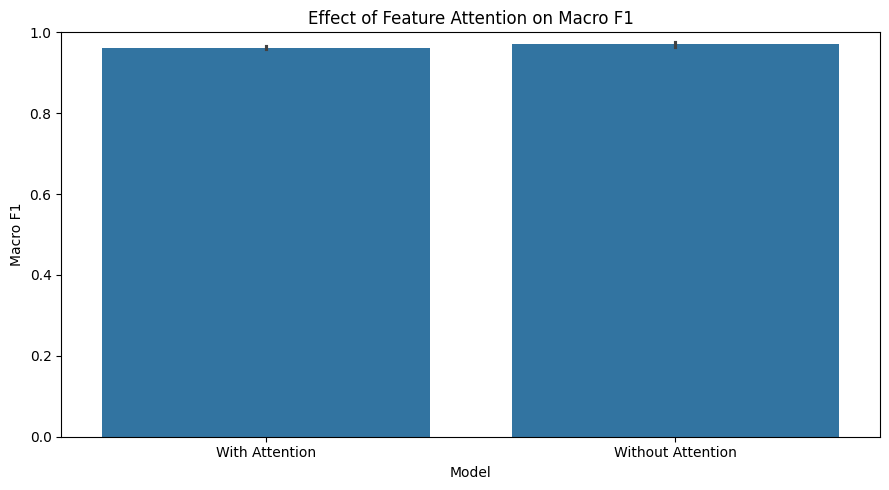

In [53]:

# ==========================================
# STEP 37: ABLATION VISUALIZATION
# ==========================================

plt.figure(figsize=(9, 5))

sns.barplot(
    data=ablation_df,
    x="Model",
    y="Macro F1",
    errorbar="sd"
)

plt.title("Effect of Feature Attention on Macro F1")

plt.ylabel("Macro F1")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


In [55]:
# 1. Check shapes
print("Data Shapes:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\ny_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)


# 2. Check subject overlap
train_subjects = set(train_df.loc[X_train.index, "subject"])
val_subjects = set(train_df.loc[X_val.index, "subject"])
test_subjects = set(test_df["subject"])

print("\nSubject Overlap:")
print("Train & Validation:", train_subjects.intersection(val_subjects))
print("Train & Test:", train_subjects.intersection(test_subjects))
print("Validation & Test:", val_subjects.intersection(test_subjects))


# 3. Check class distribution
print("\nClass Distribution:")

print("\nTrain:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nValidation:")
print(pd.Series(y_val).value_counts().sort_index())

print("\nTest:")
print(pd.Series(y_test).value_counts().sort_index())


# 4. Check missing values
print("\nMissing Values:")
print("X_train:", np.isnan(np.asarray(X_train)).sum())
print("X_val:", np.isnan(np.asarray(X_val)).sum())
print("X_test:", np.isnan(np.asarray(X_test)).sum())


# 5. Check number of unique classes
print("\nNumber of Classes:")
print("Train:", len(np.unique(y_train)))
print("Validation:", len(np.unique(y_val)))
print("Test:", len(np.unique(y_test)))

Data Shapes:
X_train: (5551, 561)
X_val: (1801, 561)
X_test: (2947, 561)

y_train: (5551,)
y_val: (1801,)
y_test: (2947,)

Subject Overlap:
Train & Validation: set()
Train & Test: set()
Validation & Test: set()

Class Distribution:

Train:
0    1076
1     993
2    1053
3     888
4     744
5     797
Name: count, dtype: int64

Validation:
0    331
1    293
2    321
3    338
4    242
5    276
Name: count, dtype: int64

Test:
Activity
LAYING                537
SITTING               491
STANDING              532
WALKING               496
WALKING_DOWNSTAIRS    420
WALKING_UPSTAIRS      471
Name: count, dtype: int64

Missing Values:
X_train: 0
X_val: 0
X_test: 0

Number of Classes:
Train: 6
Validation: 6
Test: 6


In [56]:
import inspect

print("1. Model class:")
print(inspect.signature(AdvancedHARWithoutAttention))

print("\n2. Training function:")
print(inspect.signature(train_model))

print("\n3. Scaler:")
print("scaler exists:", "scaler" in globals())

print("\n4. Label Encoder:")
print("label_encoder exists:", "label_encoder" in globals())
print("le exists:", "le" in globals())

print("\n5. Device:")
print(device)

print("\n6. Feature count:")
print(X_train.shape[1])

1. Model class:
(input_dim=561, num_classes=6, hidden_dim=256, dropout=0.3)

2. Training function:
(model, train_loader, val_loader, seed, epochs=40, learning_rate=0.001, patience=7)

3. Scaler:
scaler exists: True

4. Label Encoder:
label_encoder exists: True
le exists: False

5. Device:
cuda

6. Feature count:
561


In [57]:

import time
import torch
import torch.nn as nn
import numpy as np
import random

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


FINAL_SEED = 42
FINAL_EPOCHS = 40
LEARNING_RATE = 0.001

set_seed(FINAL_SEED)


# ==========================================
# PREPARE FINAL TRAINING DATA
# ==========================================

feature_columns = X.columns.tolist()

scaler_final = StandardScaler()

X_final = scaler_final.fit_transform(X).astype("float32")

final_dataset = TensorDataset(
    torch.tensor(X_final, dtype=torch.float32),
    torch.tensor(y_encoded, dtype=torch.long)
)

generator = torch.Generator()
generator.manual_seed(FINAL_SEED)

final_loader = DataLoader(
    final_dataset,
    batch_size=64,
    shuffle=True,
    generator=generator
)

print("Final training data ready!")


# ==========================================
# CREATE FINAL MODEL
# ==========================================

final_model = AdvancedHARWithoutAttention(
    input_dim=561,
    num_classes=6,
    hidden_dim=256,
    dropout=0.3
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=LEARNING_RATE
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

start_time = time.time()


# ==========================================
# FINAL MODEL TRAINING
# ==========================================

for epoch in range(FINAL_EPOCHS):

    final_model.train()
    total_loss = 0

    for batch_X, batch_y in final_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        outputs = final_model(batch_X)
        loss = criterion(outputs, batch_y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(final_loader)

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch [{epoch+1}/{FINAL_EPOCHS}] "
            f"Loss: {avg_loss:.4f}"
        )

if torch.cuda.is_available():
    torch.cuda.synchronize()

final_training_time = time.time() - start_time

print("\nFinal training completed!")
print("Training time:", round(final_training_time, 2), "seconds")


Final training data ready!
Epoch [5/40] Loss: 0.0767
Epoch [10/40] Loss: 0.0334
Epoch [15/40] Loss: 0.0328
Epoch [20/40] Loss: 0.0280
Epoch [25/40] Loss: 0.0244
Epoch [30/40] Loss: 0.0203
Epoch [35/40] Loss: 0.0213
Epoch [40/40] Loss: 0.0129

Final training completed!
Training time: 14.25 seconds


In [59]:
import os
import joblib
import json

SAVE_DIR = "/kaggle/working/HAR_Demo"
os.makedirs(SAVE_DIR, exist_ok=True)

# 1. Save model weights
model_path = os.path.join(
    SAVE_DIR,
    "har_model.pth"
)

torch.save(
    final_model.state_dict(),
    model_path
)

# 2. Save final scaler
scaler_path = os.path.join(
    SAVE_DIR,
    "scaler.pkl"
)

joblib.dump(scaler_final, scaler_path)

# 3. Save label encoder
encoder_path = os.path.join(
    SAVE_DIR,
    "label_encoder.pkl"
)

joblib.dump(label_encoder, encoder_path)

# 4. Save model information
metadata = {
    "model_name": "AdvancedHARWithoutAttention",
    "input_dim": 561,
    "num_classes": 6,
    "hidden_dim": 256,
    "dropout": 0.3,
    "classes": label_encoder.classes_.tolist(),
    "feature_columns": feature_columns
}

with open(
    os.path.join(SAVE_DIR, "metadata.json"),
    "w"
) as f:
    json.dump(metadata, f, indent=4)

print("All files saved successfully!")

print("\nSaved files:")
for file in os.listdir(SAVE_DIR):
    print(file)

All files saved successfully!

Saved files:
scaler.pkl
label_encoder.pkl
har_model.pth
metadata.json


Final Test Accuracy: 0.9583
Final Test Macro F1: 0.9581

Classification Report:
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       537
           SITTING       0.95      0.89      0.92       491
          STANDING       0.91      0.96      0.94       532
           WALKING       0.94      1.00      0.97       496
WALKING_DOWNSTAIRS       0.99      0.96      0.97       420
  WALKING_UPSTAIRS       0.97      0.93      0.95       471

          accuracy                           0.96      2947
         macro avg       0.96      0.96      0.96      2947
      weighted avg       0.96      0.96      0.96      2947



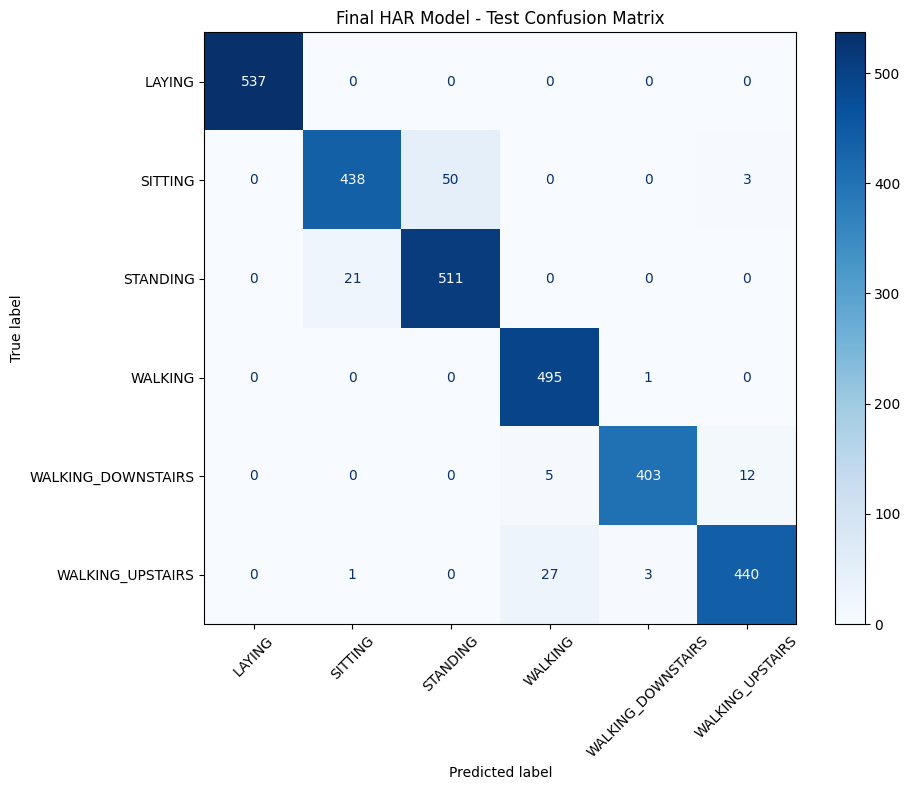

In [60]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Prepare test features using final scaler
X_test_raw = test_df[feature_columns]

X_test_final = scaler_final.transform(X_test_raw)

# Convert test labels if they are still text
if pd.Series(y_test).dtype == "object":
    y_test_final = label_encoder.transform(
        np.asarray(y_test)
    )
else:
    y_test_final = np.asarray(y_test).astype(int)

# Test tensors
X_test_tensor = torch.tensor(
    X_test_final,
    dtype=torch.float32
).to(device)

# Predict
final_model.eval()

with torch.no_grad():
    logits = final_model(X_test_tensor)
    y_pred = torch.argmax(logits, dim=1).cpu().numpy()

# Metrics
test_accuracy = accuracy_score(y_test_final, y_pred)
test_macro_f1 = f1_score(
    y_test_final,
    y_pred,
    average="macro"
)

print("Final Test Accuracy:", round(test_accuracy, 4))
print("Final Test Macro F1:", round(test_macro_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test_final,
        y_pred,
        target_names=label_encoder.classes_
    )
)

# Confusion Matrix
cm = confusion_matrix(
    y_test_final,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

plt.title("Final HAR Model - Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [62]:

wrong_indices = np.where(
    y_pred != y_test_final
)[0]

errors_df = pd.DataFrame({
    "Sample": wrong_indices,
    "Actual": label_encoder.inverse_transform(
        y_test_final[wrong_indices]
    ),
    "Predicted": label_encoder.inverse_transform(
        y_pred[wrong_indices]
    )
})

print("Total errors:", len(errors_df))
display(errors_df.head(15))

display(
    errors_df.groupby(["Actual", "Predicted"])
    .size()
    .sort_values(ascending=False)
    .reset_index(name="Count")
)


Total errors: 123


,Sample,Actual,Predicted
0,38,SITTING,STANDING
1,42,SITTING,STANDING
2,43,SITTING,STANDING
3,46,SITTING,STANDING
4,50,SITTING,STANDING
5,182,SITTING,STANDING
6,198,SITTING,STANDING
7,305,STANDING,SITTING
8,313,STANDING,SITTING
9,448,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS


,Actual,Predicted,Count
0,SITTING,STANDING,50
1,WALKING_UPSTAIRS,WALKING,27
2,STANDING,SITTING,21
3,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS,12
4,WALKING_DOWNSTAIRS,WALKING,5
5,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,3
6,SITTING,WALKING_UPSTAIRS,3
7,WALKING,WALKING_DOWNSTAIRS,1
8,WALKING_UPSTAIRS,SITTING,1


In [63]:
import shutil

shutil.make_archive(
    "/kaggle/working/HAR_Demo",
    "zip",
    SAVE_DIR
)

print("ZIP created successfully!")

ZIP created successfully!
